<a href="https://colab.research.google.com/github/codedbyraquel/prompt-engineering-lab/blob/main/notebooks/prompt_engineering_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Hello, AI Engineering!")

Hello, AI Engineering!


In [2]:
import pandas as pd

In [7]:

# Importação da biblioteca Pandas
import pandas as pd

# Endereço do dataset no GitHub
url = "https://raw.githubusercontent.com/codedbyraquel/prompt-engineering-lab/main/data/reviews_complex.csv"

# Carregamento dos dados
df = pd.read_csv(url)

# Visualização dos primeiros registros
df.head()


,id,review,expected_sentiment,challenge
0,11,Parabéns pela entrega! Só demorou duas horas.,negativo,sarcasmo
1,12,"Mto bommm, chegou rapidin e quentinho.",positivo,linguagem_informal
2,13,O pedido foi entregue às 19h30.,neutro,factual
3,14,"A pizza estava perfeita, pena que veio faltand...",misto,contradicao
4,15,"Nossa, adorei pagar caro pra receber comida fria.",negativo,ironia


In [11]:
df.shape
df.info()
df.isnull().sum()
df.duplicated().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  20 non-null     int64 
 1   review              20 non-null     object
 2   expected_sentiment  20 non-null     object
 3   challenge           20 non-null     object
dtypes: int64(1), object(3)
memory usage: 772.0+ bytes


np.int64(0)

In [12]:
df["expected_sentiment"].value_counts()

,count
expected_sentiment,
negativo,5
positivo,5
neutro,5
misto,5


<Axes: title={'center': 'Distribuição dos sentimentos'}, xlabel='expected_sentiment'>

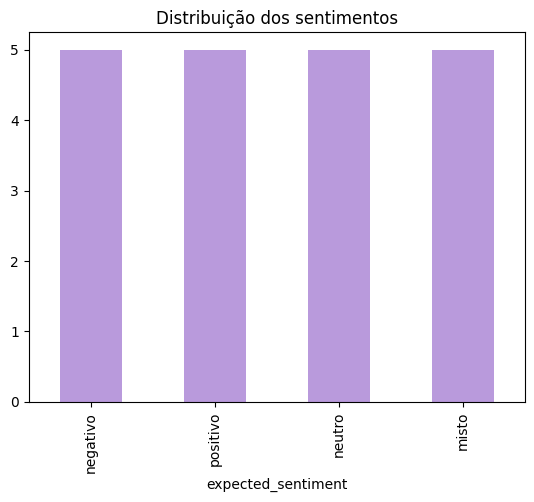

In [13]:
df["expected_sentiment"].value_counts().plot(
    kind="bar",
    color="#B99ADC",
    title="Distribuição dos sentimentos"
)

In [14]:
import requests

url_zero = "https://raw.githubusercontent.com/codedbyraquel/prompt-engineering-lab/main/prompts/zero-shot.md"

response = requests.get(url_zero)

response.raise_for_status()

zero_shot = response.text

print(zero_shot)


# Zero-shot Prompting

## Objetivo

Classificar o sentimento presente em avaliações de restaurantes utilizando um modelo de linguagem, sem fornecer exemplos prévios.

## Prompt

Atue como um sistema de análise de sentimentos especializado em avaliações de restaurantes.

Analise a avaliação fornecida e classifique seu sentimento em uma das seguintes categorias:

- positivo
- negativo
- neutro
- misto

Considere a qualidade da comida, o atendimento e a experiência de entrega, quando mencionados.

Não invente informações que não estejam presentes na avaliação.

Retorne apenas a categoria correspondente.

Avaliação: {review}



In [15]:
url_few = "https://raw.githubusercontent.com/codedbyraquel/prompt-engineering-lab/main/prompts/few-shot.md"

response = requests.get(url_few)

response.raise_for_status()

few_shot = response.text

print(few_shot)



# Few-shot Prompting

## Objetivo

Classificar sentimentos em avaliações de restaurantes
utilizando exemplos para orientar o modelo de linguagem.

## Prompt

Atue como um sistema de análise de sentimentos especializado
em avaliações de restaurantes.

Classifique cada avaliação em uma das seguintes categorias:

- positivo
- negativo
- neutro
- misto

Considere a qualidade da comida, o atendimento e a entrega.

Não invente informações que não estejam presentes na avaliação.

Utilize os exemplos abaixo como referência:

Exemplo 1:
Avaliação: O lanche estava delicioso e bem preparado.
Classificação: positivo

Exemplo 2:
Avaliação: A embalagem estava aberta e faltavam itens.
Classificação: negativo

Exemplo 3:
Avaliação: Recebi os dois pratos que solicitei.
Classificação: neutro

Exemplo 4:
Avaliação: O atendimento foi excelente, mas a sobremesa
estava ruim.
Classificação: misto

Retorne apenas a categoria correspondente.

Avaliação: {review}



In [17]:
review = df["review"].iloc[0]

print(review)

zero_template = zero_shot.split("## Prompt", 1)[-1].strip()

few_template = few_shot.split("## Prompt", 1)[-1].strip()

Parabéns pela entrega! Só demorou duas horas.


In [18]:
prompt_final = zero_template.replace("{review}", review)

print(prompt_final)

Atue como um sistema de análise de sentimentos especializado em avaliações de restaurantes.

Analise a avaliação fornecida e classifique seu sentimento em uma das seguintes categorias:

- positivo
- negativo
- neutro
- misto

Considere a qualidade da comida, o atendimento e a experiência de entrega, quando mencionados.

Não invente informações que não estejam presentes na avaliação.

Retorne apenas a categoria correspondente.

Avaliação: Parabéns pela entrega! Só demorou duas horas.


In [19]:
from google.colab import userdata

api_key = userdata.get("GEMINI_API_KEY")

print("Chave carregada!" if api_key else "Chave vazia!")

Chave carregada!


In [21]:
%pip install -q google-genai


In [22]:
from google import genai

client = genai.Client(api_key=api_key)

In [29]:
response = client.models.generate_content(
    model="gemini-3.1-flash-lite",
    contents=prompt_final
)

print(response.text)

misto


In [31]:
def classify_review(review, template):
    prompt = template.replace("{review}", review)

    response = client.models.generate_content(
        model="gemini-3.1-flash-lite",
        contents=prompt
    )

    return response.text.strip().lower()

In [32]:
results = []

for _, row in df.head(3).iterrows():

    predicted = classify_review(
        row["review"],
        zero_template
    )

    results.append({
        "id": row["id"],
        "expected_sentiment": row["expected_sentiment"],
        "predicted_sentiment": predicted,
        "correct": predicted == row["expected_sentiment"]
    })

results_df = pd.DataFrame(results)

display(results_df)

,id,expected_sentiment,predicted_sentiment,correct
0,11,negativo,misto,False
1,12,positivo,positivo,True
2,13,neutro,neutro,True


In [34]:

results_zero = results_df.to_dict("records")

for _, row in df.iloc[3:].iterrows():

    predicted = classify_review(
        row["review"],
        zero_template
    )

    results_zero.append({
        "id": row["id"],
        "expected_sentiment": row["expected_sentiment"],
        "predicted_sentiment": predicted,
        "correct": predicted == row["expected_sentiment"]
    })

    print(row["id"], predicted)


14 misto
15 negativo
16 positivo
17 neutro
18 misto
19 negativo
20 positivo
21 neutro
22 misto
23 negativo
24 positivo
25 neutro
26 misto
27 negativo
28 positivo
29 neutro
30 misto


In [35]:
zero_results_df = pd.DataFrame(results_zero)

display(zero_results_df)

,id,expected_sentiment,predicted_sentiment,correct
0,11,negativo,misto,False
1,12,positivo,positivo,True
2,13,neutro,neutro,True
3,14,misto,misto,True
4,15,negativo,negativo,True
5,16,positivo,positivo,True
6,17,neutro,neutro,True
7,18,misto,misto,True
8,19,negativo,negativo,True
9,20,positivo,positivo,True


In [37]:
accuracy_zero = zero_results_df["correct"].mean()

print(f"Acurácia Zero-shot: {accuracy_zero:.2%}")

Acurácia Zero-shot: 95.00%


In [38]:
results_few = []

In [39]:

for _, row in df.iloc[len(results_few):].iterrows():

    predicted = classify_review(
        row["review"],
        few_template
    )

    results_few.append({
        "id": row["id"],
        "expected_sentiment": row["expected_sentiment"],
        "predicted_sentiment": predicted,
        "correct": predicted == row["expected_sentiment"]
    })

    print(row["id"], predicted)


11 misto
12 positivo
13 neutro
14 misto
15 negativo
16 positivo
17 neutro
18 misto
19 negativo
20 positivo
21 neutro
22 misto
23 negativo
24 positivo
25 neutro
26 classificação: misto
27 negativo
28 positivo
29 neutro
30 misto


In [40]:
few_results_df = pd.DataFrame(results_few)

display(few_results_df)

,id,expected_sentiment,predicted_sentiment,correct
0,11,negativo,misto,False
1,12,positivo,positivo,True
2,13,neutro,neutro,True
3,14,misto,misto,True
4,15,negativo,negativo,True
5,16,positivo,positivo,True
6,17,neutro,neutro,True
7,18,misto,misto,True
8,19,negativo,negativo,True
9,20,positivo,positivo,True


In [41]:
accuracy_few = few_results_df["correct"].mean()

print(f"Acurácia Few-shot: {accuracy_few:.2%}")

Acurácia Few-shot: 90.00%


In [42]:
print(f"Acurácia Zero-shot: {accuracy_zero:.2%}")

print(f"Acurácia Few-shot: {accuracy_few:.2%}")

Acurácia Zero-shot: 95.00%
Acurácia Few-shot: 90.00%


In [43]:
print("Erros do Zero-shot:")
display(zero_results_df[zero_results_df["correct"] == False])

print("Erros do Few-shot:")
display(few_results_df[few_results_df["correct"] == False])


Erros do Zero-shot:


,id,expected_sentiment,predicted_sentiment,correct
0,11,negativo,misto,False


Erros do Few-shot:


,id,expected_sentiment,predicted_sentiment,correct
0,11,negativo,misto,False
15,26,misto,classificação: misto,False


In [44]:
comparison = pd.DataFrame({
    "Técnica": ["Zero-shot", "Few-shot"],
    "Acurácia": [accuracy_zero * 100, accuracy_few * 100]
})

display(comparison)


,Técnica,Acurácia
0,Zero-shot,95.0
1,Few-shot,90.0


<Axes: title={'center': 'Comparação de técnicas de Prompt Engineering'}, xlabel='Técnica'>

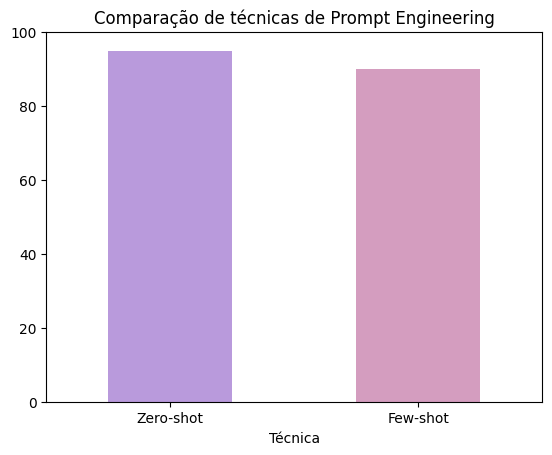

In [45]:
comparison.plot(
    x="Técnica",
    y="Acurácia",
    kind="bar",
    color=["#B99ADC", "#D49DBF"],
    title="Comparação de técnicas de Prompt Engineering",
    ylim=(0, 100),
    legend=False,
    rot=0
)


In [46]:
def normalize_sentiment(text):
    text = text.strip().lower()
    text = text.removeprefix("classificação:").strip()

    return text

In [47]:
print(normalize_sentiment("classificação: misto"))

misto


In [49]:
for result in [zero_results_df, few_results_df]:

    result["normalized_sentiment"] = result[
        "predicted_sentiment"
    ].apply(normalize_sentiment)

    result["correct_normalized"] = (
        result["normalized_sentiment"] ==
        result["expected_sentiment"]
    )

In [50]:
accuracy_zero_normalized = zero_results_df["correct_normalized"].mean()

accuracy_few_normalized = few_results_df["correct_normalized"].mean()

print(f"Zero-shot: {accuracy_zero_normalized:.2%}")
print(f"Few-shot: {accuracy_few_normalized:.2%}")

Zero-shot: 95.00%
Few-shot: 95.00%


In [51]:
zero_results_df.to_csv(
    "zero-shot-gemini.csv",
    index=False
)

few_results_df.to_csv(
    "few-shot-gemini.csv",
    index=False
)

In [52]:
from google.colab import files

files.download("zero-shot-gemini.csv")
files.download("few-shot-gemini.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>